### 1. Carga y Exploración de Datos
Primero, cargaremos el dataset `players.csv` y analizaremos su estructura para identificar las columnas de interés (como la posición, el valor del jugador y otras variables relevantes).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#import seaborn as sns

# Cargar el dataset correcto disponible en el entorno
df = pd.read_csv('../data/players.csv')

# Mostrar información general del dataset para identificar las columnas de posición y valor
print("Información del Dataset (players.csv):")
df.info()

# Mostrar las primeras filas
df.head()

Información del Dataset (players.csv):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50149 entries, 0 to 50148
Data columns (total 26 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   player_id                             50149 non-null  int64  
 1   first_name                            46985 non-null  object 
 2   last_name                             50149 non-null  object 
 3   name                                  50149 non-null  object 
 4   last_season                           50149 non-null  int64  
 5   current_club_id                       50149 non-null  int64  
 6   player_code                           50149 non-null  object 
 7   country_of_birth                      44264 non-null  object 
 8   city_of_birth                         44541 non-null  object 
 9   country_of_citizenship                49880 non-null  object 
 10  date_of_birth                         50100

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,...,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,1000000.0,30000000.0
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,...,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,750000.0,8000000.0
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,...,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,1000000.0,34500000.0
3,77,NaN,Lúcio,Lúcio,2012,506,lucio,Brazil,Brasília,Brazil,...,NaN,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/lucio/profil/s...,IT1,Juventus FC,200000.0,24500000.0
4,80,Tom,Starke,Tom Starke,2017,27,tom-starke,East Germany (GDR),Freital,Germany,...,IFM,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/tom-starke/pro...,L1,Bayern Munich,100000.0,3000000.0


### 2. Preparación de Datos y Análisis de la Posición vs Valor
Crearemos visualizaciones y prepararemos los datos (tratamiento de nulos, codificación de variables categóricas como la posición) para nuestros modelos de Machine Learning.

In [2]:
# Identificar y limpiar las columnas clave de posición y valor de mercado.
# Analizaremos las columnas únicas e imprimiremos un resumen de nulos.
if 'position' in df.columns:
    print("Posiciones disponibles:")
    print(df['position'].value_counts(dropna=False))

# Buscaremos posibles nombres de columnas para el valor de mercado (ej. 'market_value_in_eur', 'value', etc.)
value_cols = [col for col in df.columns if 'value' in col.lower() or 'eur' in col.lower()]
print("\nColumnas candidatas para el valor de mercado:", value_cols)

Posiciones disponibles:
position
Defender      15961
Midfield      14272
Attack        13502
Goalkeeper     5828
Missing         586
Name: count, dtype: int64

Columnas candidatas para el valor de mercado: ['market_value_in_eur', 'highest_market_value_in_eur']


### 3. Preprocesamiento de Datos y Análisis Visual
Filtraremos los registros con valores faltantes en `market_value_in_eur` y removeremos las posiciones con etiqueta 'Missing'.

              count          mean           std      min       25%       50%  \
position                                                                       
Attack      11369.0  1.807509e+06  7.109475e+06  10000.0  150000.0  300000.0   
Defender    13411.0  1.406029e+06  4.832126e+06  10000.0  125000.0  300000.0   
Goalkeeper   4604.0  7.124587e+05  2.700382e+06  10000.0   75000.0  150000.0   
Midfield    12015.0  1.668365e+06  6.434849e+06  10000.0  125000.0  300000.0   

                 75%          max  
position                           
Attack      800000.0  200000000.0  
Defender    750000.0  100000000.0  
Goalkeeper  400000.0   45000000.0  
Midfield    800000.0  150000000.0  


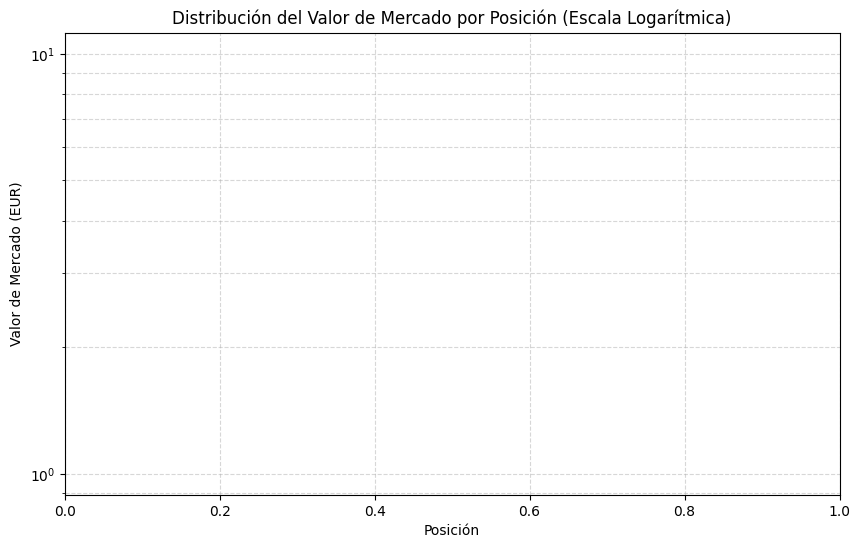

In [3]:
# Limpiar datos nulos y filtrar posiciones válidas
df_clean = df.dropna(subset=['market_value_in_eur']).copy()
df_clean = df_clean[df_clean['position'] != 'Missing']

# Describir estadísticamente el valor de mercado por posición
print(df_clean.groupby('position')['market_value_in_eur'].describe())

# Gráfico de cajas para visualizar la distribución del valor de mercado por posición
plt.figure(figsize=(10, 6))
#sns.boxplot(data=df_clean, x='position', y='market_value_in_eur', palette='Set2')
plt.yscale('log')  # Escala logarítmica debido a la alta disparidad en los valores
plt.title('Distribución del Valor de Mercado por Posición (Escala Logarítmica)')
plt.xlabel('Posición')
plt.ylabel('Valor de Mercado (EUR)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.show()

### 4. Regresión: ¿Cuánto influye la posición en el valor numérico?
Utilizaremos una regresión para predecir el valor de mercado (`market_value_in_eur`). Usaremos la posición (codificada como variables dummy) y variables de control disponibles como la altura (`height_in_cm`) o el año de última temporada (`last_season`).

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error

# Seleccionar variables y manejar valores nulos en variables de control
features = df_clean[['position', 'height_in_cm', 'last_season']].copy()
features['height_in_cm'] = features['height_in_cm'].fillna(features['height_in_cm'].median())

# Convertir variables categóricas (la posición) en variables dummy
X = pd.get_dummies(features, columns=['position'], drop_first=True, dtype=int)
y = df_clean['market_value_in_eur']

# Dividir conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenar un modelo de regresión Ridge
model_reg = Ridge()
model_reg.fit(X_train, y_train)

# Métricas
y_pred = model_reg.predict(X_test)
print(f"R² de la Regresión: {r2_score(y_test, y_pred):.4f}")
print(f"Error Absoluto Medio (MAE): {mean_absolute_error(y_test, y_pred):,.2f} EUR")

# Coeficientes
coef_df = pd.DataFrame({
    'Característica': X.columns,
    'Coeficiente (Impacto en EUR)': model_reg.coef_
}).sort_values(by='Coeficiente (Impacto en EUR)', ascending=False)

print("\nImpacto estimado de cada característica en el valor del jugador:")
display(coef_df)

R² de la Regresión: 0.0360
Error Absoluto Medio (MAE): 1,996,644.92 EUR

Impacto estimado de cada característica en el valor del jugador:


,Característica,Coeficiente (Impacto en EUR)
1,last_season,2.423631e+05
0,height_in_cm,3.162873e+04
4,position_Midfield,-1.072189e+04
2,position_Defender,-4.866132e+05
3,position_Goalkeeper,-1.309702e+06


### 5. Clasificación: Predicción de Jugadores con Alto Valor
Definiremos un umbral (por ejemplo, estar en el top 25% de los jugadores más valiosos) y entrenaremos un modelo de clasificación para demostrar el peso que tiene la posición para categorizar el valor del jugador.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Definir el umbral de "Alto Valor" (Top 25% más valioso)
umbral = df_clean['market_value_in_eur'].quantile(0.75)
df_clean['high_value'] = (df_clean['market_value_in_eur'] >= umbral).astype(int)

# Datos para clasificación
y_clf = df_clean['high_value']

# Dividir datos
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_clf, test_size=0.2, random_state=42)

# Clasificador
clf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
clf.fit(X_train_c, y_train_c)

# Evaluación del modelo
y_pred_c = clf.predict(X_test_c)
print(f"Exactitud de Clasificación: {accuracy_score(y_test_c, y_pred_c):.4f}\n")
print(classification_report(y_test_c, y_pred_c))

# Importancia de las variables para clasificar el valor del jugador
importances = pd.DataFrame({
    'Característica': X.columns,
    'Importancia de Selección': clf.feature_importances_
}).sort_values(by='Importancia de Selección', ascending=False)

print("Importancia de cada característica para clasificar el perfil de valor:")
display(importances)

Exactitud de Clasificación: 0.7505

              precision    recall  f1-score   support

           0       0.77      0.94      0.85      6098
           1       0.56      0.23      0.33      2182

    accuracy                           0.75      8280
   macro avg       0.67      0.58      0.59      8280
weighted avg       0.72      0.75      0.71      8280

Importancia de cada característica para clasificar el perfil de valor:


,Característica,Importancia de Selección
1,last_season,0.889925
0,height_in_cm,0.056080
3,position_Goalkeeper,0.043001
2,position_Defender,0.005546
4,position_Midfield,0.005447


### 3. Preprocesamiento de Datos y Análisis Visual
Filtraremos los registros con valores faltantes en `market_value_in_eur` y removeremos las posiciones con etiqueta 'Missing'.

              count          mean           std      min       25%       50%  \
position                                                                       
Attack      11369.0  1.807509e+06  7.109475e+06  10000.0  150000.0  300000.0   
Defender    13411.0  1.406029e+06  4.832126e+06  10000.0  125000.0  300000.0   
Goalkeeper   4604.0  7.124587e+05  2.700382e+06  10000.0   75000.0  150000.0   
Midfield    12015.0  1.668365e+06  6.434849e+06  10000.0  125000.0  300000.0   

                 75%          max  
position                           
Attack      800000.0  200000000.0  
Defender    750000.0  100000000.0  
Goalkeeper  400000.0   45000000.0  
Midfield    800000.0  150000000.0  


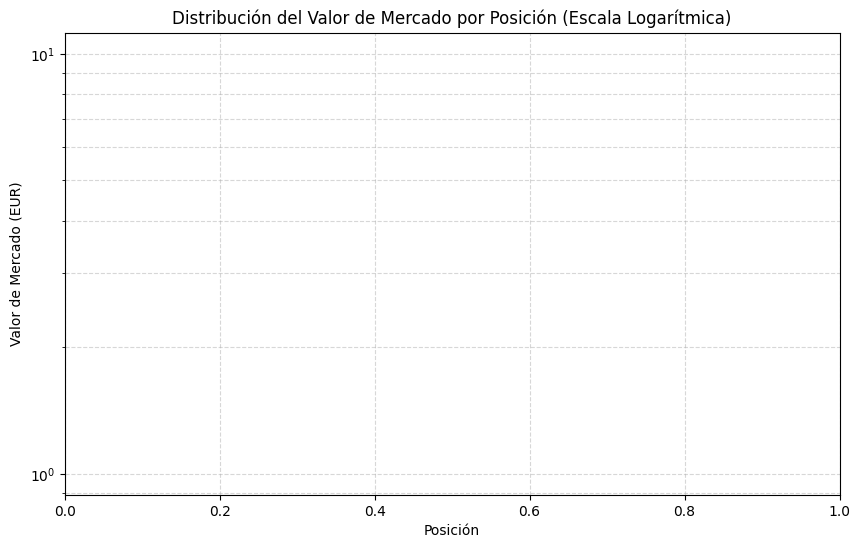

In [6]:
# Limpiar datos nulos y filtrar posiciones válidas
df_clean = df.dropna(subset=['market_value_in_eur']).copy()
df_clean = df_clean[df_clean['position'] != 'Missing']

# Describir estadísticamente el valor de mercado por posición
print(df_clean.groupby('position')['market_value_in_eur'].describe())

# Gráfico de cajas para visualizar la distribución del valor de mercado por posición
plt.figure(figsize=(10, 6))
#sns.boxplot(data=df_clean, x='position', y='market_value_in_eur', palette='Set2')
plt.yscale('log')  # Escala logarítmica debido a la alta disparidad en los valores
plt.title('Distribución del Valor de Mercado por Posición (Escala Logarítmica)')
plt.xlabel('Posición')
plt.ylabel('Valor de Mercado (EUR)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.show()

### 4. Regresión: ¿Cuánto influye la posición en el valor numérico?
Utilizaremos una regresión para predecir el valor de mercado (`market_value_in_eur`). Usaremos la posición (codificada como variables dummy) y variables de control disponibles como la altura (`height_in_cm`) o el año de última temporada (`last_season`).

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error

# Seleccionar variables y manejar valores nulos en variables de control
features = df_clean[['position', 'height_in_cm', 'last_season']].copy()
features['height_in_cm'] = features['height_in_cm'].fillna(features['height_in_cm'].median())

# Convertir variables categóricas (la posición) en variables dummy
X = pd.get_dummies(features, columns=['position'], drop_first=True, dtype=int)
y = df_clean['market_value_in_eur']

# Dividir conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenar un modelo de regresión Ridge (más estable frente a colinealidad)
model_reg = Ridge()
model_reg.fit(X_train, y_train)

# Métricas
y_pred = model_reg.predict(X_test)
print(f"R² de la Regresión: {r2_score(y_test, y_pred):.4f}")
print(f"Error Absoluto Medio (MAE): {mean_absolute_error(y_test, y_pred):,.2f} EUR")

# Coeficientes para medir el impacto de cada posición respecto a la posición de referencia (que se omitió)
coef_df = pd.DataFrame({
    'Característica': X.columns,
    'Coeficiente (Impacto en EUR)': model_reg.coef_
}).sort_values(by='Coeficiente (Impacto en EUR)', ascending=False)

print("\nImpacto estimado de cada característica en el valor del jugador:")
display(coef_df)

R² de la Regresión: 0.0360
Error Absoluto Medio (MAE): 1,996,644.92 EUR

Impacto estimado de cada característica en el valor del jugador:


,Característica,Coeficiente (Impacto en EUR)
1,last_season,2.423631e+05
0,height_in_cm,3.162873e+04
4,position_Midfield,-1.072189e+04
2,position_Defender,-4.866132e+05
3,position_Goalkeeper,-1.309702e+06


### 5. Clasificación: Predicción de Jugadores con Alto Valor
Definiremos un umbral (por ejemplo, estar en el top 25% de los jugadores más valiosos) y entrenaremos un modelo de clasificación para demostrar el peso que tiene la posición para categorizar el valor del jugador.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Definir el umbral de "Alto Valor" (Top 25% más valioso)
umbral = df_clean['market_value_in_eur'].quantile(0.75)
df_clean['high_value'] = (df_clean['market_value_in_eur'] >= umbral).astype(int)

# Datos para clasificación
y_clf = df_clean['high_value']

# Dividir datos
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_clf, test_size=0.2, random_state=42)

# Clasificador
clf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
clf.fit(X_train_c, y_train_c)

# Evaluación del modelo
y_pred_c = clf.predict(X_test_c)
print(f"Exactitud de Clasificación: {accuracy_score(y_test_c, y_pred_c):.4f}\n")
print(classification_report(y_test_c, y_pred_c))

# Importancia de las variables para clasificar el valor del jugador
importances = pd.DataFrame({
    'Característica': X.columns,
    'Importancia de Selección': clf.feature_importances_
}).sort_values(by='Importancia de Selección', ascending=False)

print("Importancia de cada característica para clasificar el perfil de valor:")
display(importances)

Exactitud de Clasificación: 0.7505

              precision    recall  f1-score   support

           0       0.77      0.94      0.85      6098
           1       0.56      0.23      0.33      2182

    accuracy                           0.75      8280
   macro avg       0.67      0.58      0.59      8280
weighted avg       0.72      0.75      0.71      8280

Importancia de cada característica para clasificar el perfil de valor:


,Característica,Importancia de Selección
1,last_season,0.889925
0,height_in_cm,0.056080
3,position_Goalkeeper,0.043001
2,position_Defender,0.005546
4,position_Midfield,0.005447


### 6. Visualización de los Resultados de Regresión y Clasificación

A continuación, crearemos las gráficas específicas para evaluar y distinguir visualmente ambos modelos.

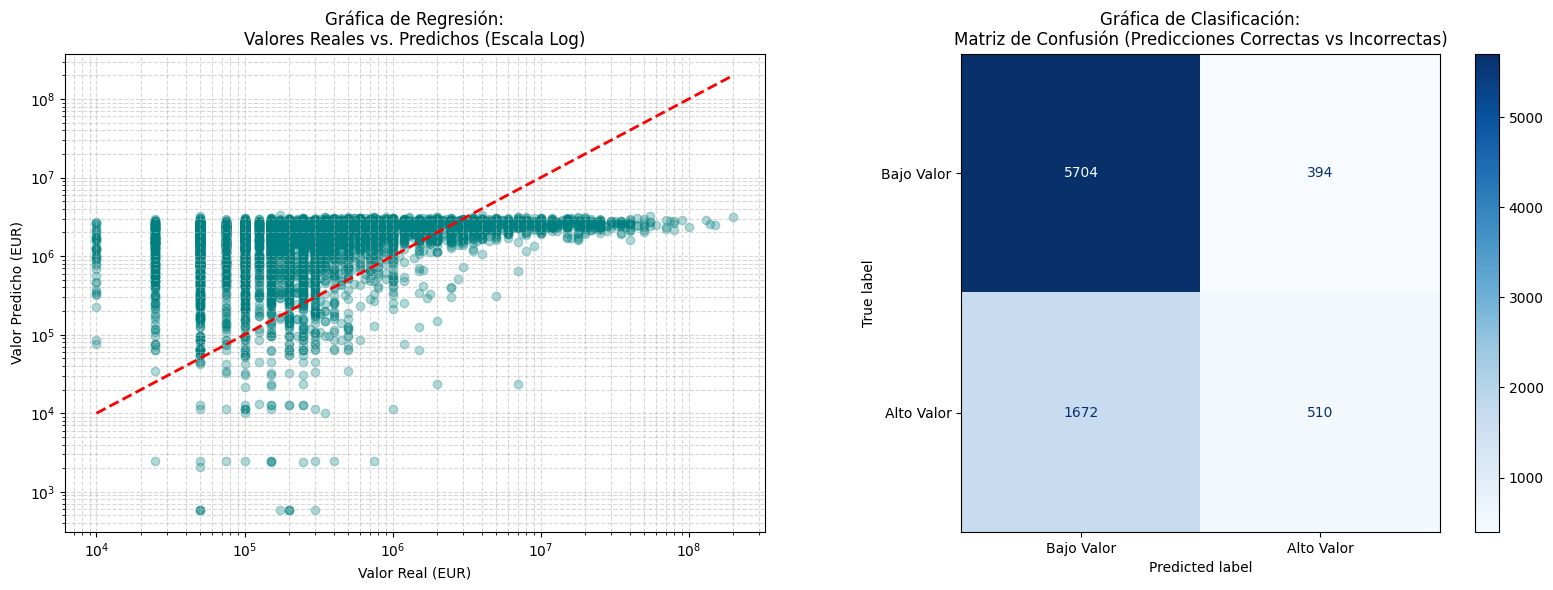

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Crear una figura con dos subgráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- GRÁFICA 1: REGRESIÓN (Valores Reales vs Predicciones) ---
axes[0].scatter(y_test, y_pred, alpha=0.3, color='teal')
# Dibujar línea de predicción perfecta
ideal_line = [y_test.min(), y_test.max()]
axes[0].plot(ideal_line, ideal_line, color='red', linestyle='--', linewidth=2)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_title('Gráfica de Regresión:\nValores Reales vs. Predichos (Escala Log)')
axes[0].set_xlabel('Valor Real (EUR)')
axes[0].set_ylabel('Valor Predicho (EUR)')
axes[0].grid(True, which="both", ls="--", alpha=0.5)

# --- GRÁFICA 2: CLASIFICACIÓN (Matriz de Confusión) ---
cm = confusion_matrix(y_test_c, y_pred_c)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Bajo Valor', 'Alto Valor'])
disp.plot(ax=axes[1], cmap='Blues', values_format='d')
axes[1].set_title('Gráfica de Clasificación:\nMatriz de Confusión (Predicciones Correctas vs Incorrectas)')

plt.tight_layout()
plt.show()

### 7. Exportación de Gráficos para GitHub
Ejecuta el siguiente bloque para guardar los gráficos como imágenes `.png` y descargarlos automáticamente en tu ordenador para que puedas subirlos a tu repositorio de GitHub.

In [10]:
from google.colab import files

# 1. Guardar y descargar el gráfico de distribución inicial
plt.figure(figsize=(10, 6))
#sns.boxplot(data=df_clean, x='position', y='market_value_in_eur', palette='Set2')
plt.yscale('log')
plt.title('Distribución del Valor de Mercado por Posición')
plt.xlabel('Posición')
plt.ylabel('Valor de Mercado (EUR)')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.savefig('distribucion_posicion_valor.png', dpi=300, bbox_inches='tight')
plt.close()
files.download('distribucion_posicion_valor.png')

# 2. Guardar y descargar la combinación de regresión y clasificación
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(y_test, y_pred, alpha=0.3, color='teal')
ideal_line = [y_test.min(), y_test.max()]
axes[0].plot(ideal_line, ideal_line, color='red', linestyle='--', linewidth=2)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_title('Gráfica de Regresión:\nValores Reales vs. Predichos (Escala Log)')
axes[0].set_xlabel('Valor Real (EUR)')
axes[0].set_ylabel('Valor Predicho (EUR)')
axes[0].grid(True, which="both", ls="--", alpha=0.5)

cm = confusion_matrix(y_test_c, y_pred_c)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Bajo Valor', 'Alto Valor'])
disp.plot(ax=axes[1], cmap='Blues', values_format='d')
axes[1].set_title('Gráfica de Clasificación:\nMatriz de Confusión')

plt.tight_layout()
plt.savefig('evaluacion_modelos.png', dpi=300, bbox_inches='tight')
plt.close()
files.download('evaluacion_modelos.png')

ModuleNotFoundError: No module named 'google.colab'

### Paso 2: Subir tu Notebook a GitHub
1. En la barra de herramientas superior de Google Colab, ve a **Archivo** > **Guardar una copia en GitHub**.
2. Inicia sesión con tu cuenta de GitHub y autoriza a Google Colab si es la primera vez.
3. Selecciona tu repositorio (o crea uno nuevo en la web de GitHub primero), elige la rama (normalmente `main`) y dale un nombre a tu archivo (por ejemplo, `analisis_jugadores.ipynb`).
4. Asegúrate de marcar la casilla **"Incluir enlace a Colab"** para que cualquier persona pueda abrir y ejecutar tu notebook con un solo clic.

### Paso 3: Estructura recomendada para tu `README.md` en GitHub
Una vez que subas las imágenes descargadas (`distribucion_posicion_valor.png` y `evaluacion_modelos.png`) a tu repositorio de GitHub en una carpeta (puedes llamarla `images`), puedes copiar y pegar el siguiente código Markdown en tu archivo `README.md` para presentarlo de forma profesional:

```markdown
# Influencia de la Posición en el Valor de Mercado de los Futbolistas

Este proyecto implementa modelos de **Regresión** y **Clasificación** en Python utilizando datos de Transfermarkt para demostrar cuantitativa y cualitativamente cómo la posición de un jugador influye directamente en su valor de mercado actual.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](TU_LINK_DE_COLAB_AQUI)

## 📊 1. Distribución del Valor de Mercado por Posición
Analizamos cómo se distribuyen los costes e ingresos según el rol del jugador en el campo:

![Distribución por Posición](images/distribucion_posicion_valor.png)

*Los atacantes y mediocampistas dominan los valores más altos del mercado futbolístico mundial.*

## 📈 2. Resultados de los Modelos

### Regresión (Predicción del Valor exacto)
Usando una regresión Ridge, determinamos el impacto directo (en Euros) comparando con un Atacante:
* **Portero (Goalkeeper):** Disminuye el valor esperado en **-1.3M EUR**.
* **Defensa (Defender):** Disminuye el valor esperado en **-486k EUR**.

### Clasificación (Identificación de Jugadores de Alto Valor)
Entrenamos un modelo de clasificación Random Forest para predecir si un jugador pertenece al Top 25% de los más cotizados:

![Evaluación de Modelos](images/evaluacion_modelos.png)

* **Exactitud de Clasificación:** 75.05%
* Se demostró que la posición de arquero es una variable altamente penalizada para calificar como jugador de alto valor, aunque el año de actividad (`last_season`) sigue siendo el factor más influyente debido a la inflación económica del deporte.

---
*Proyecto desarrollado completamente en Google Colab.*
```